In [40]:
import pandas as pd
from datetime import date, timedelta
import datetime
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima_model import ARIMA
import statsmodels.api as sm
import warnings


In [41]:
df=pd.read_csv('/content/adidas-quarterly-sales.csv')
df.head()

,Time Period,Revenue
0,2000Q1,1517
1,2000Q2,1248
2,2000Q3,1677
3,2000Q4,1393
4,2001Q1,1558


In [42]:
print(df.shape)
print(df.dtypes)
print(df.info())
print(df.describe())
print(df.columns)

(88, 2)
Time Period    object
Revenue         int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Time Period  88 non-null     object
 1   Revenue      88 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.5+ KB
None
           Revenue
count    88.000000
mean   3302.034091
std    1477.855719
min    1078.000000
25%    1864.250000
50%    3162.000000
75%    4457.500000
max    6410.000000
Index(['Time Period', 'Revenue'], dtype='object')


In [43]:
#dataframe
df = pd.DataFrame(df)
print(df.head(25))


   Time Period  Revenue
0       2000Q1     1517
1       2000Q2     1248
2       2000Q3     1677
3       2000Q4     1393
4       2001Q1     1558
5       2001Q2     1368
6       2001Q3     1790
7       2001Q4     1396
8       2002Q1     1638
9       2002Q2     1507
10      2002Q3     1868
11      2002Q4     1510
12      2003Q1     1669
13      2003Q2     1392
14      2003Q3     1853
15      2003Q4     1353
16      2004Q1     1623
17      2004Q2     1401
18      2004Q3     1758
19      2004Q4     1078
20      2005Q1     1674
21      2005Q2     1516
22      2005Q3     1924
23      2005Q4     1522
24      2006Q1     2459


In [44]:
#missing value
df.isnull().sum()

,0
Time Period,0
Revenue,0


In [45]:
import yfinance as yf
# Define the ticker symbol
ticker_symbol = "AAPL"

# Create a Ticker object
ticker_data = yf.Ticker(ticker_symbol)

# Get historical data
historical_data = ticker_data.history(period="5y")

# Print the data
print(historical_data)

                                 Open        High         Low       Close  \
Date                                                                        
2020-02-18 00:00:00-05:00   76.531249   77.596613   76.349240   77.414604   
2020-02-19 00:00:00-05:00   77.657300   78.766345   77.657300   78.535797   
2020-02-20 00:00:00-05:00   78.295518   78.785727   77.222874   77.730072   
2020-02-21 00:00:00-05:00   77.322389   77.766496   75.351836   75.970665   
2020-02-24 00:00:00-05:00   72.138769   73.818104   70.190057   72.362030   
...                               ...         ...         ...         ...   
2025-02-10 00:00:00-05:00  229.570007  230.589996  227.199997  227.649994   
2025-02-11 00:00:00-05:00  228.199997  235.229996  228.130005  232.619995   
2025-02-12 00:00:00-05:00  231.199997  236.960007  230.679993  236.869995   
2025-02-13 00:00:00-05:00  236.910004  242.339996  235.570007  241.529999   
2025-02-14 00:00:00-05:00  241.250000  245.550003  240.990005  244.600006   

In [46]:
# Convert Time Period to datetime format
df['Year'] = df['Time Period'].str[:4].astype(int)
df['Month'] = df['Time Period'].str[5:7].astype(int)
df['Day'] = 1
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df.head(25)

,Time Period,Revenue,Year,Month,Day,Date
0,2000Q1,1517,2000,1,1,2000-01-01
1,2000Q2,1248,2000,2,1,2000-02-01
2,2000Q3,1677,2000,3,1,2000-03-01
3,2000Q4,1393,2000,4,1,2000-04-01
4,2001Q1,1558,2001,1,1,2001-01-01
5,2001Q2,1368,2001,2,1,2001-02-01
6,2001Q3,1790,2001,3,1,2001-03-01
7,2001Q4,1396,2001,4,1,2001-04-01
8,2002Q1,1638,2002,1,1,2002-01-01
9,2002Q2,1507,2002,2,1,2002-02-01


In [47]:
# Sort data by Date
df = df.sort_values(by='Date')
df.head(25)

,Time Period,Revenue,Year,Month,Day,Date
0,2000Q1,1517,2000,1,1,2000-01-01
1,2000Q2,1248,2000,2,1,2000-02-01
2,2000Q3,1677,2000,3,1,2000-03-01
3,2000Q4,1393,2000,4,1,2000-04-01
4,2001Q1,1558,2001,1,1,2001-01-01
5,2001Q2,1368,2001,2,1,2001-02-01
6,2001Q3,1790,2001,3,1,2001-03-01
7,2001Q4,1396,2001,4,1,2001-04-01
8,2002Q1,1638,2002,1,1,2002-01-01
9,2002Q2,1507,2002,2,1,2002-02-01


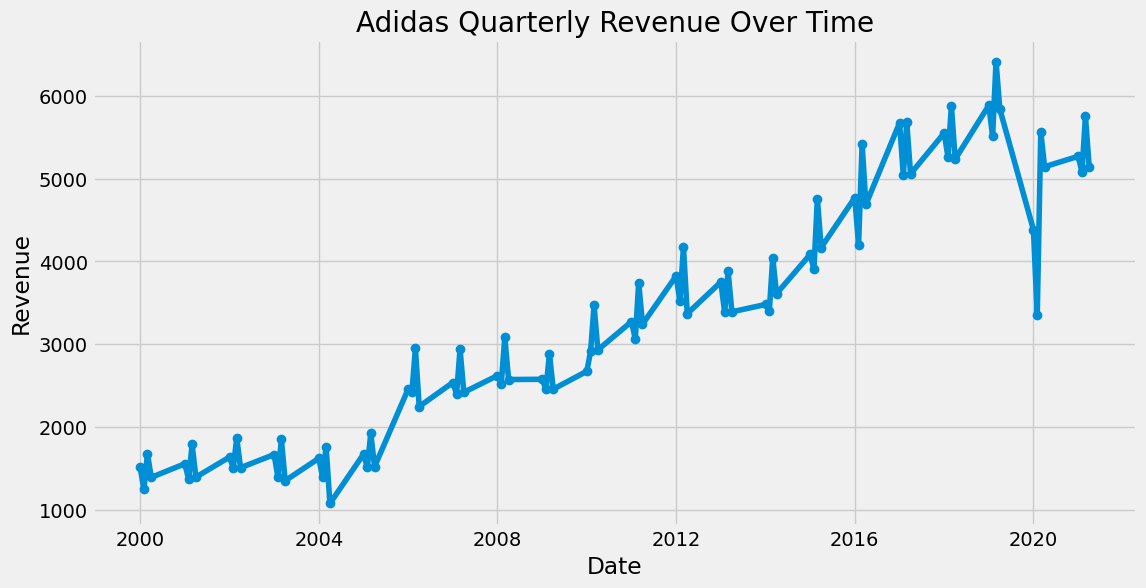

In [48]:
# Plot revenue trend over time
plt.figure(figsize=(12, 6))
plt.plot(df['Date'], df['Revenue'], marker='o', linestyle='-')
plt.title('Adidas Quarterly Revenue Over Time')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

In [49]:
# Summary statistics
print(df['Revenue'].describe())

count      88.000000
mean     3302.034091
std      1477.855719
min      1078.000000
25%      1864.250000
50%      3162.000000
75%      4457.500000
max      6410.000000
Name: Revenue, dtype: float64


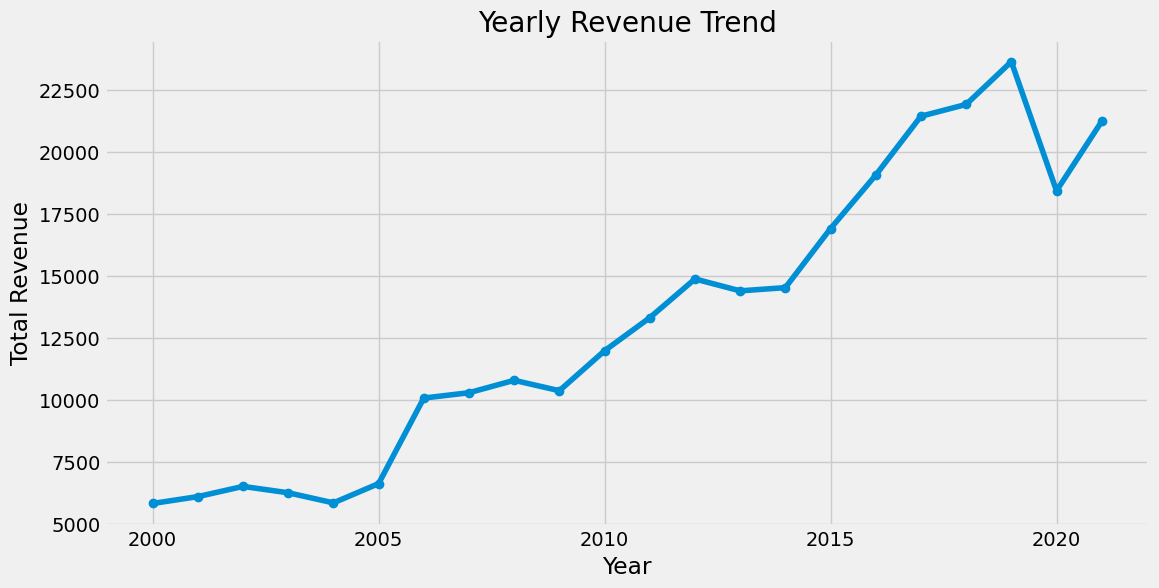

In [50]:
# Yearly revenue trend
yearly_revenue = df.groupby(df['Date'].dt.year)['Revenue'].sum()
plt.figure(figsize=(12, 6))
plt.plot(yearly_revenue.index, yearly_revenue.values, marker='o', linestyle='-')
plt.title('Yearly Revenue Trend')
plt.xlabel('Year')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.show()


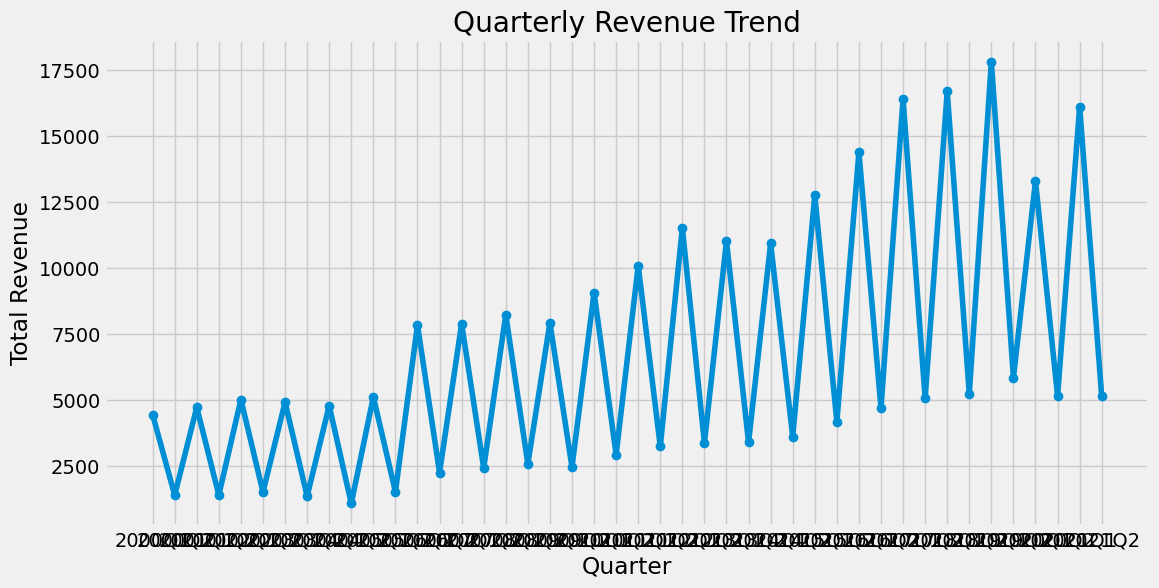

In [51]:
# Quarterly trend analysis
df['Quarter'] = df['Date'].dt.to_period('Q')
quarterly_revenue = df.groupby(df['Quarter'])['Revenue'].sum()
plt.figure(figsize=(12, 6))
plt.plot(quarterly_revenue.index.astype(str), quarterly_revenue.values, marker='o', linestyle='-')
plt.title('Quarterly Revenue Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.show()

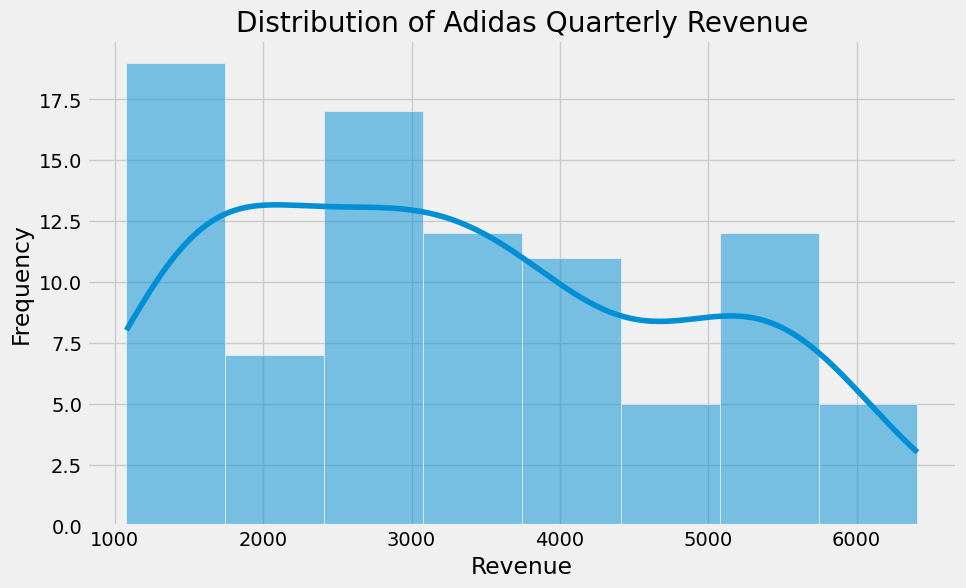

In [52]:
# Visualize the distribution of sales
import seaborn as sns # Importing seaborn library and assigning it to the alias 'sns'

plt.figure(figsize=(10, 6))
sns.histplot(df['Revenue'], kde=True)
plt.title('Distribution of Adidas Quarterly Revenue')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.show()

In [53]:
df.corr(numeric_only=True)

,Revenue,Year,Month,Day
Revenue,1.000000,9.425899e-01,2.230357e-02,NaN
Year,0.942590,1.000000e+00,-2.282359e-15,NaN
Month,0.022304,-2.282359e-15,1.000000e+00,NaN
Day,NaN,NaN,NaN,NaN


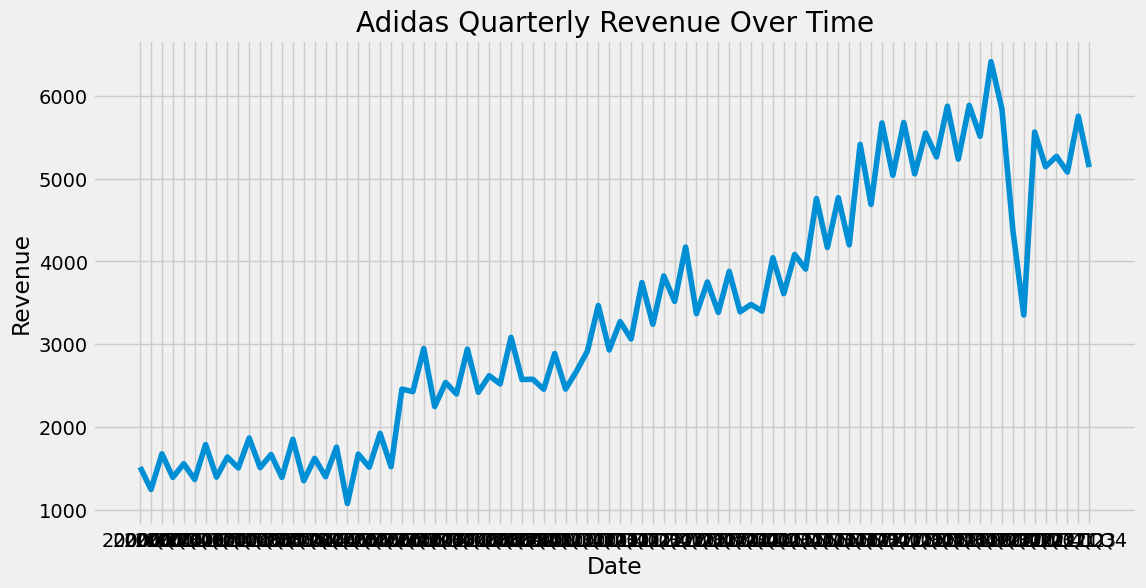

In [54]:
# Time series plot of sales
plt.figure(figsize=(12, 6))
# Replace 'Date' with the actual column name from your DataFrame if it's different
plt.plot(df['Time Period'], df['Revenue'])
plt.title('Adidas Quarterly Revenue Over Time')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

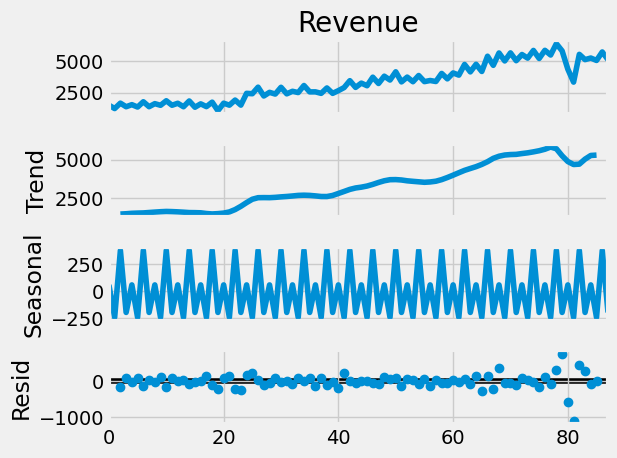

In [55]:
# Seasonal decomposition
decomposition = seasonal_decompose(df['Revenue'], model='additive', period=4) # Assuming quarterly data
fig = decomposition.plot()
plt.show()

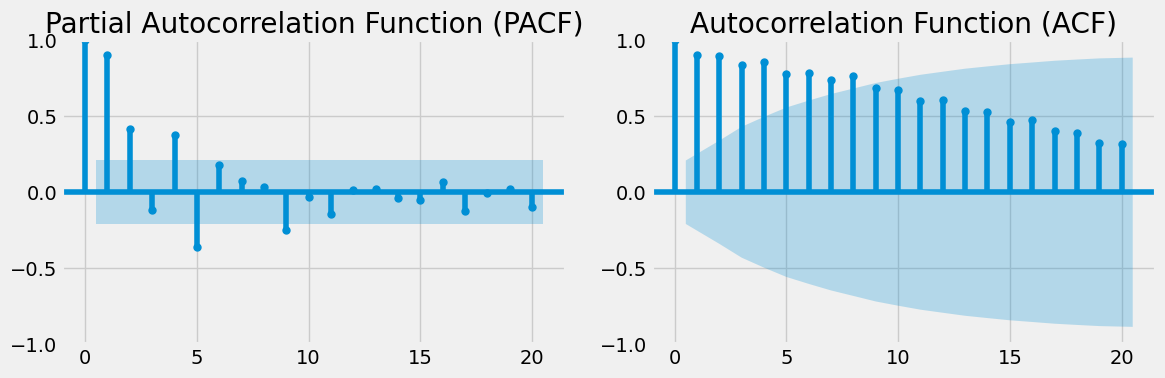

In [56]:
# Autocorrelation and Partial Autocorrelation Functions (ACF and PACF)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_pacf(df['Revenue'], lags=20, ax=axes[0])
axes[0].set_title('Partial Autocorrelation Function (PACF)')
sm.graphics.tsa.plot_acf(df['Revenue'], lags=20, ax=axes[1])
axes[1].set_title('Autocorrelation Function (ACF)')
plt.tight_layout()
plt.show()

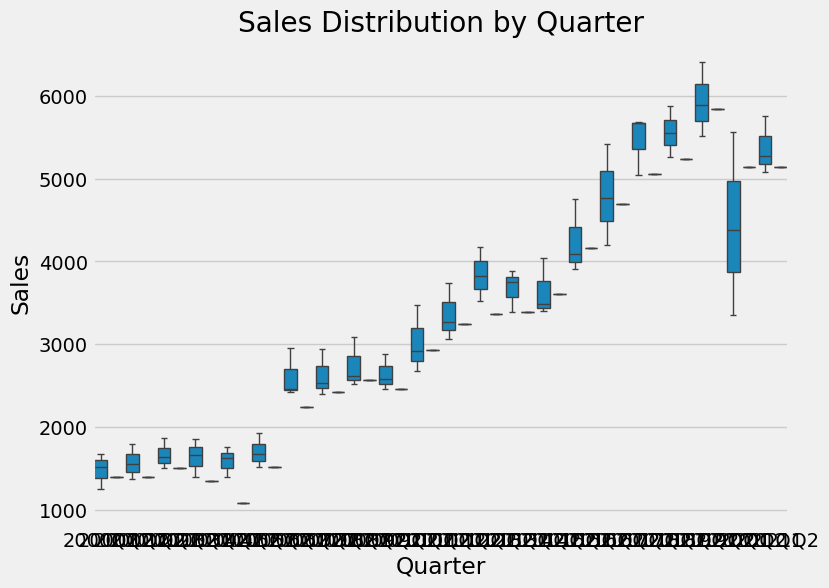

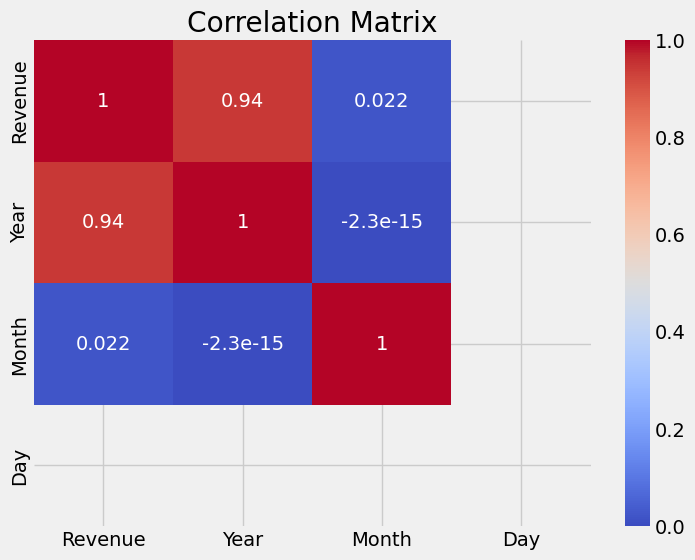

In [57]:
# Boxplot of sales by quarter (if applicable) - Assuming 'Quarter' column exists
if 'Quarter' in df.columns:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='Quarter', y='Revenue', data=df)
    plt.title('Sales Distribution by Quarter')
    plt.xlabel('Quarter')
    plt.ylabel('Sales')
    plt.show()
    # Correlation heatmap (if more numerical features exist)
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


In [58]:
# Feature Engineering:
df['Revenue_Lag1'] = df['Revenue'].shift(1)
df['Revenue_Lag2'] = df['Revenue'].shift(2)
df['Revenue_RollingMean'] = df['Revenue'].rolling(window=3).mean()
df['Revenue_RollingStd'] = df['Revenue'].rolling(window=3).std()
df.head(25)



,Time Period,Revenue,Year,Month,Day,Date,Quarter,Revenue_Lag1,Revenue_Lag2,Revenue_RollingMean,Revenue_RollingStd
0,2000Q1,1517,2000,1,1,2000-01-01,2000Q1,NaN,NaN,NaN,NaN
1,2000Q2,1248,2000,2,1,2000-02-01,2000Q1,1517.0,NaN,NaN,NaN
2,2000Q3,1677,2000,3,1,2000-03-01,2000Q1,1248.0,1517.0,1480.666667,216.795603
3,2000Q4,1393,2000,4,1,2000-04-01,2000Q2,1677.0,1248.0,1439.333333,218.220836
4,2001Q1,1558,2001,1,1,2001-01-01,2001Q1,1393.0,1677.0,1542.666667,142.619541
5,2001Q2,1368,2001,2,1,2001-02-01,2001Q1,1558.0,1393.0,1439.666667,103.239204
6,2001Q3,1790,2001,3,1,2001-03-01,2001Q1,1368.0,1558.0,1572.000000,211.348054
7,2001Q4,1396,2001,4,1,2001-04-01,2001Q2,1790.0,1368.0,1518.000000,235.974575
8,2002Q1,1638,2002,1,1,2002-01-01,2002Q1,1396.0,1790.0,1608.000000,198.705813
9,2002Q2,1507,2002,2,1,2002-02-01,2002Q1,1638.0,1396.0,1513.666667,121.137663


In [70]:
df['Quarter_Sin'] = np.sin(2 * np.pi * df['Quarter'].dt.quarter / 4)
df['Quarter_Cos'] = np.cos(2 * np.pi * df['Quarter'].dt.quarter / 4)
df.head(25)

,Revenue,Year,Month,Day,Date,Quarter,Revenue_Lag1,Revenue_Lag2,Revenue_RollingMean,Revenue_RollingStd,Revenue_Lag4,Revenue_RollingMean_4,Revenue_RollingStd_4,Quarter_Sin,Quarter_Cos
Time Period,,,,,,,,,,,,,,,
2000Q1,1517,2000,1,1,2000-01-01,2000Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,6.123234e-17
2000Q2,1248,2000,2,1,2000-02-01,2000Q1,1517.0,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,6.123234e-17
2000Q3,1677,2000,3,1,2000-03-01,2000Q1,1248.0,1517.0,1480.666667,216.795603,NaN,NaN,NaN,1.000000e+00,6.123234e-17
2000Q4,1393,2000,4,1,2000-04-01,2000Q2,1677.0,1248.0,1439.333333,218.220836,NaN,1458.75,182.359306,1.224647e-16,-1.000000e+00
2001Q1,1558,2001,1,1,2001-01-01,2001Q1,1393.0,1677.0,1542.666667,142.619541,1517.0,1469.00,187.795989,1.000000e+00,6.123234e-17
2001Q2,1368,2001,2,1,2001-02-01,2001Q1,1558.0,1393.0,1439.666667,103.239204,1248.0,1499.00,145.558694,1.000000e+00,6.123234e-17
2001Q3,1790,2001,3,1,2001-03-01,2001Q1,1368.0,1558.0,1572.000000,211.348054,1677.0,1527.25,194.393716,1.000000e+00,6.123234e-17
2001Q4,1396,2001,4,1,2001-04-01,2001Q2,1790.0,1368.0,1518.000000,235.974575,1393.0,1528.00,193.707684,1.224647e-16,-1.000000e+00
2002Q1,1638,2002,1,1,2002-01-01,2002Q1,1396.0,1790.0,1608.000000,198.705813,1558.0,1548.00,201.798579,1.000000e+00,6.123234e-17


In [59]:
#Consider external factors: Incorporate external data that might influence sales, such as economic indicators, marketing campaigns, or competitor information. You can find such data from sources like the World Bank, Google Trends, or industry reports. Join this data with your existing DataFrame based on the corresponding time periods.
## Time Series Forecasting using ARIMA
# Set Date as index
df.set_index('Time Period', inplace=True)
df.head(25)

,Revenue,Year,Month,Day,Date,Quarter,Revenue_Lag1,Revenue_Lag2,Revenue_RollingMean,Revenue_RollingStd
Time Period,,,,,,,,,,
2000Q1,1517,2000,1,1,2000-01-01,2000Q1,NaN,NaN,NaN,NaN
2000Q2,1248,2000,2,1,2000-02-01,2000Q1,1517.0,NaN,NaN,NaN
2000Q3,1677,2000,3,1,2000-03-01,2000Q1,1248.0,1517.0,1480.666667,216.795603
2000Q4,1393,2000,4,1,2000-04-01,2000Q2,1677.0,1248.0,1439.333333,218.220836
2001Q1,1558,2001,1,1,2001-01-01,2001Q1,1393.0,1677.0,1542.666667,142.619541
2001Q2,1368,2001,2,1,2001-02-01,2001Q1,1558.0,1393.0,1439.666667,103.239204
2001Q3,1790,2001,3,1,2001-03-01,2001Q1,1368.0,1558.0,1572.000000,211.348054
2001Q4,1396,2001,4,1,2001-04-01,2001Q2,1790.0,1368.0,1518.000000,235.974575
2002Q1,1638,2002,1,1,2002-01-01,2002Q1,1396.0,1790.0,1608.000000,198.705813


In [60]:
from statsmodels.tsa.arima.model import ARIMA
#ARIMA/SARIMA: Based on your ACF and PACF plots, you can experiment with different ARIMA or SARIMA model configurations. Use the ARIMA or SARIMAX classes from the statsmodels library to fit the models. Evaluate model performance using metrics like AICc, BIC, and RMSE.
model = ARIMA(df['Revenue'], order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                Revenue   No. Observations:                   88
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -640.084
Date:                Mon, 17 Feb 2025   AIC                           1286.167
Time:                        17:26:43   BIC                           1293.565
Sample:                    01-01-2000   HQIC                          1289.146
                         - 10-01-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9991      0.005   -186.972      0.000      -1.010      -0.989
ma.L1          0.9502      0.059     16.064      0.000       0.834       1.066
sigma2      1.404e+05   1.07e+04     13.158      0.0

In [73]:
#2. Hyperparameter Tuning and Cross-Validation
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)
for train_index, test_index in tscv.split(df):
    train_data, test_data = df.iloc[train_index], df.iloc[test_index]
    model = ARIMA(train_data['Revenue'], order=(1, 1, 1))
    model_fit = model.fit()
    forecast = model_fit.forecast(steps=len(test_data))
    print(forecast)


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


2004-07-01    1608.451987
2004-10-01    1445.904641
2005-01-01    1573.267314
2005-04-01    1473.473310
2005-07-01    1551.666104
2005-10-01    1490.398766
2006-01-01    1538.404299
2006-04-01    1500.789947
2006-07-01    1530.262371
2006-10-01    1507.169489
2007-01-01    1525.263732
2007-04-01    1511.086133
2007-07-01    1522.194878
2007-10-01    1513.490709
Freq: QS-OCT, Name: predicted_mean, dtype: float64
2008-01-01    2825.033144
2008-04-01    2420.602983
2008-07-01    2824.431059
2008-10-01    2421.204172
2009-01-01    2823.830765
2009-04-01    2421.803572
2009-07-01    2823.232257
2009-10-01    2422.401189
2010-01-01    2822.635530
2010-04-01    2422.997028
2010-07-01    2822.040578
2010-10-01    2423.591094
2011-01-01    2821.447396
2011-04-01    2424.183393
Freq: QS-OCT, Name: predicted_mean, dtype: float64


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


2011-07-01    3403.728668
2011-10-01    3064.000899
2012-01-01    3403.727769
2012-04-01    3064.001798
2012-07-01    3403.726870
2012-10-01    3064.002697
2013-01-01    3403.725971
2013-04-01    3064.003596
2013-07-01    3403.725072
2013-10-01    3064.004496
2014-01-01    3403.724173
2014-04-01    3064.005395
2014-07-01    3403.723274
2014-10-01    3064.006294
Freq: QS-OCT, Name: predicted_mean, dtype: float64
2015-01-01    3983.844533
2015-04-01    3610.022262
2015-07-01    3983.822272
2015-10-01    3610.044522
2016-01-01    3983.800014
2016-04-01    3610.066780
2016-07-01    3983.777758
2016-10-01    3610.089034
2017-01-01    3983.755505
2017-04-01    3610.111286
2017-07-01    3983.733254
2017-10-01    3610.133535
2018-01-01    3983.711006
2018-04-01    3610.155782
Freq: QS-OCT, Name: predicted_mean, dtype: float64
2018-07-01    5832.485597
2018-10-01    5262.704182
2019-01-01    5830.786497
2019-04-01    5264.398215
2019-07-01    5829.097516
2019-10-01    5266.082159
2020-01-01    

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


/usr/local/lib/python3.11/dist-packages/prophet/forecaster.py:1133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  self.history_dates = pd.to_datetime(pd.Series(df['ds'].unique(), name='ds')).sort_values()
/usr/local/lib/python3.11/dist-packages/prophet/forecaster.py:287: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ds'] = pd.to_datetime(df['ds'])
INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpuamfn_c6/ocf2vj44.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpuamfn_c6/_eanxk39.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:

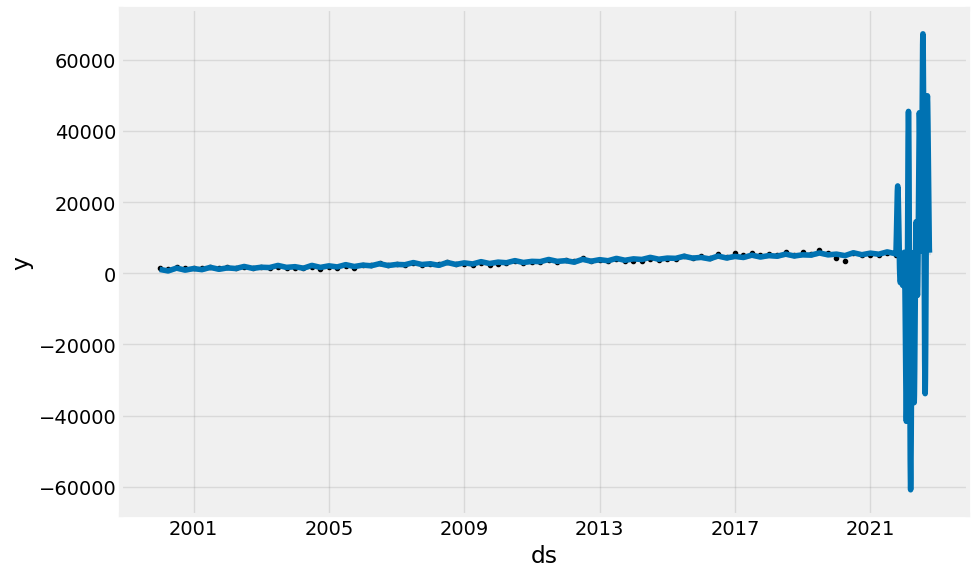

In [79]:
#Prophet: Prophet is a time series forecasting library developed by Facebook. It is particularly effective for data with seasonality and trend changes. You can install it using pip install prophet. Prophet provides an intuitive interface for model fitting and forecasting.
!pip install prophet
from prophet import Prophet
model = Prophet()
model.fit(df.reset_index().rename(columns={'Time Period': 'ds', 'Revenue': 'y'}))
future = model.make_future_dataframe(periods=365)
forecast = model.predict(future)
model.plot(forecast)
plt.show()

In [62]:
df['Revenue_Lag4'] = df['Revenue'].shift(4)  # Lag of 4 quarters
df['Revenue_RollingMean_4'] = df['Revenue'].rolling(window=4).mean()  # Rolling mean of 4 quarters
df['Revenue_RollingStd_4'] = df['Revenue'].rolling(window=4).std()  # Rolling standard deviation of 4 quarters
df.head(25)

,Revenue,Year,Month,Day,Date,Quarter,Revenue_Lag1,Revenue_Lag2,Revenue_RollingMean,Revenue_RollingStd,Revenue_Lag4,Revenue_RollingMean_4,Revenue_RollingStd_4
Time Period,,,,,,,,,,,,,
2000Q1,1517,2000,1,1,2000-01-01,2000Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000Q2,1248,2000,2,1,2000-02-01,2000Q1,1517.0,NaN,NaN,NaN,NaN,NaN,NaN
2000Q3,1677,2000,3,1,2000-03-01,2000Q1,1248.0,1517.0,1480.666667,216.795603,NaN,NaN,NaN
2000Q4,1393,2000,4,1,2000-04-01,2000Q2,1677.0,1248.0,1439.333333,218.220836,NaN,1458.75,182.359306
2001Q1,1558,2001,1,1,2001-01-01,2001Q1,1393.0,1677.0,1542.666667,142.619541,1517.0,1469.00,187.795989
2001Q2,1368,2001,2,1,2001-02-01,2001Q1,1558.0,1393.0,1439.666667,103.239204,1248.0,1499.00,145.558694
2001Q3,1790,2001,3,1,2001-03-01,2001Q1,1368.0,1558.0,1572.000000,211.348054,1677.0,1527.25,194.393716
2001Q4,1396,2001,4,1,2001-04-01,2001Q2,1790.0,1368.0,1518.000000,235.974575,1393.0,1528.00,193.707684
2002Q1,1638,2002,1,1,2002-01-01,2002Q1,1396.0,1790.0,1608.000000,198.705813,1558.0,1548.00,201.798579


In [64]:
df['Revenue_Lag4'] = df['Revenue'].shift(4)  # Lag of 4 quarters
df['Revenue_RollingMean_4'] = df['Revenue'].rolling(window=4).mean()  # Rolling mean of 4 quarters
df['Revenue_RollingStd_4'] = df['Revenue'].rolling(window=4).std()  # Rolling standard deviation of 4 quarters
df.head(25)

,Revenue,Year,Month,Day,Date,Quarter,Revenue_Lag1,Revenue_Lag2,Revenue_RollingMean,Revenue_RollingStd,Revenue_Lag4,Revenue_RollingMean_4,Revenue_RollingStd_4
Time Period,,,,,,,,,,,,,
2000Q1,1517,2000,1,1,2000-01-01,2000Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000Q2,1248,2000,2,1,2000-02-01,2000Q1,1517.0,NaN,NaN,NaN,NaN,NaN,NaN
2000Q3,1677,2000,3,1,2000-03-01,2000Q1,1248.0,1517.0,1480.666667,216.795603,NaN,NaN,NaN
2000Q4,1393,2000,4,1,2000-04-01,2000Q2,1677.0,1248.0,1439.333333,218.220836,NaN,1458.75,182.359306
2001Q1,1558,2001,1,1,2001-01-01,2001Q1,1393.0,1677.0,1542.666667,142.619541,1517.0,1469.00,187.795989
2001Q2,1368,2001,2,1,2001-02-01,2001Q1,1558.0,1393.0,1439.666667,103.239204,1248.0,1499.00,145.558694
2001Q3,1790,2001,3,1,2001-03-01,2001Q1,1368.0,1558.0,1572.000000,211.348054,1677.0,1527.25,194.393716
2001Q4,1396,2001,4,1,2001-04-01,2001Q2,1790.0,1368.0,1518.000000,235.974575,1393.0,1528.00,193.707684
2002Q1,1638,2002,1,1,2002-01-01,2002Q1,1396.0,1790.0,1608.000000,198.705813,1558.0,1548.00,201.798579


In [66]:
from statsmodels.tsa.arima.model import ARIMA
#ARIMA/SARIMA: Based on your ACF and PACF plots, you can experiment with different ARIMA or SARIMA model configurations. Use the ARIMA or SARIMAX classes from the statsmodels library to fit the models. Evaluate model performance using metrics like AICc, BIC, and RMSE
model = ARIMA(df['Revenue'], order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                Revenue   No. Observations:                   88
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -640.084
Date:                Mon, 17 Feb 2025   AIC                           1286.167
Time:                        17:29:30   BIC                           1293.565
Sample:                    01-01-2000   HQIC                          1289.146
                         - 10-01-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9991      0.005   -186.972      0.000      -1.010      -0.989
ma.L1          0.9502      0.059     16.064      0.000       0.834       1.066
sigma2      1.404e+05   1.07e+04     13.158      0.0

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


/usr/local/lib/python3.11/dist-packages/prophet/forecaster.py:1133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  self.history_dates = pd.to_datetime(pd.Series(df['ds'].unique(), name='ds')).sort_values()
/usr/local/lib/python3.11/dist-packages/prophet/forecaster.py:287: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ds'] = pd.to_datetime(df['ds'])
INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpuamfn_c6/_l2q_q74.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpuamfn_c6/bdu5wqqn.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:

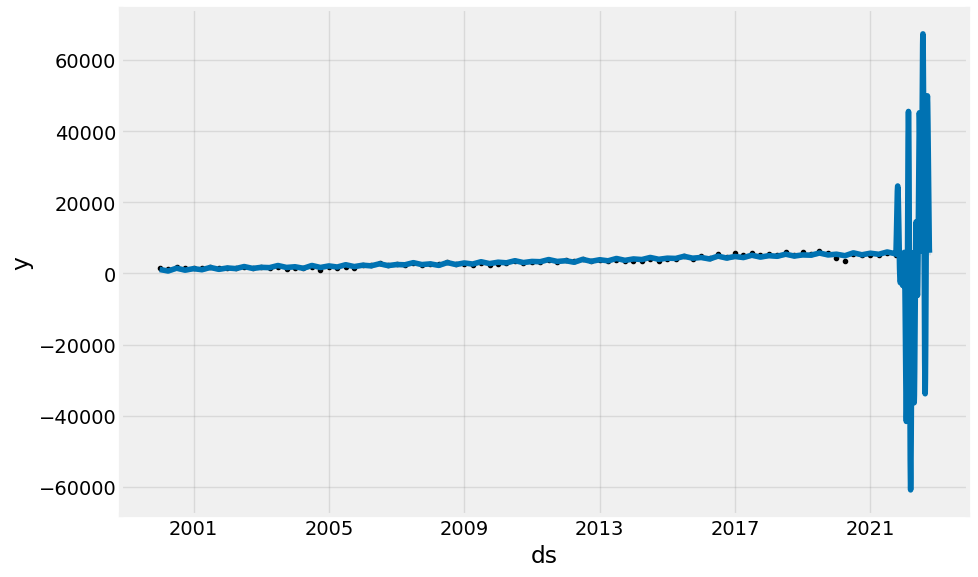

In [67]:
from prophet import Prophet
model = Prophet()
model.fit(df.reset_index().rename(columns={'Time Period': 'ds', 'Revenue': 'y'}))  # Prophet expects specific column names
future = model.make_future_dataframe(periods=365) # For a 1-year forecast
forecast = model.predict(future)
model.plot(forecast)
plt.show()

In [69]:
# prompt: # Model Evaluation Metrics

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Assuming 'forecast' DataFrame from Prophet contains 'yhat' (predictions) and 'yhat_lower', 'yhat_upper'
# Also assuming 'df' contains the actual values ('Revenue') for the same time period as the forecast

# Extract actual and predicted values
y_true = df['Revenue'][-len(forecast['yhat']):]  # Match the length of the forecast
y_pred = forecast['yhat'][-len(y_true):]

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"RMSE: {rmse}")

# Calculate MAE
mae = mean_absolute_error(y_true, y_pred)
print(f"MAE: {mae}")


# Calculate MAPE (Mean Absolute Percentage Error)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mape = mean_absolute_percentage_error(y_true, y_pred)
print(f"MAPE: {mape}")


# Calculate R-squared
from sklearn.metrics import r2_score
r2 = r2_score(y_true, y_pred)
print(f"R-squared: {r2}")


RMSE: 35125.61558096338
MAE: 30132.13594495039
MAPE: 1314.3061352049735
R-squared: -570.4092075608293


In [81]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarima_model = SARIMAX(df['Revenue'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_model_fit = sarima_model.fit()
print(sarima_model_fit.summary())


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:559: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _index = to_datetime(index)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                            Revenue   No. Observations:                   88
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -548.282
Date:                            Mon, 17 Feb 2025   AIC                           1106.564
Time:                                    17:43:53   BIC                           1118.152
Sample:                                01-01-2000   HQIC                          1111.191
                                     - 10-01-2021                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7176      0.053     13.636      0.000       0.614       0.821
ma.L1         -0.9981      0.546   

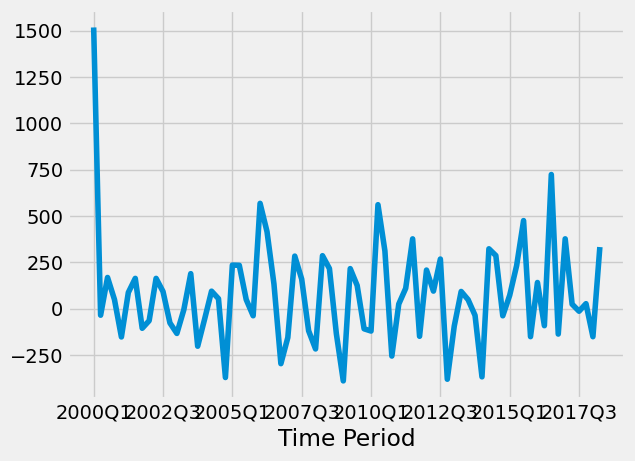

In [82]:
# Example: Analyzing residuals from ARIMA model
residuals = model_fit.resid
residuals.plot()
plt.show()

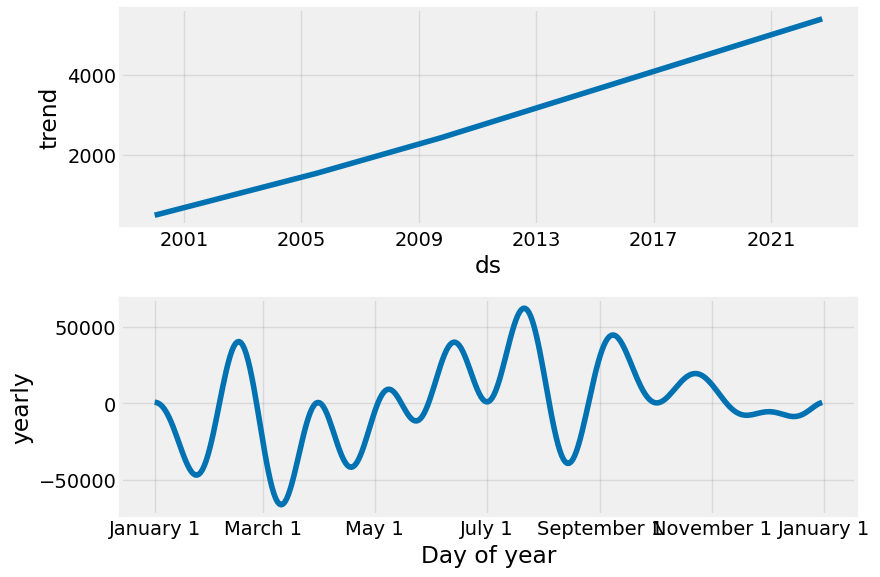

In [86]:
import pandas as pd
from prophet import Prophet
import matplotlib.pyplot as plt

# Assuming you have your data in a DataFrame called 'df'
# and have already fitted your Prophet model as 'model'

# 1. Access component contributions:
forecast = model.predict(model.make_future_dataframe(periods=365))

# Remove weekly seasonality components from the list as they are not present
forecast_components = forecast[['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper',
                                 'additive_terms', 'additive_terms_lower', 'additive_terms_upper',
                                 'yearly', 'yearly_lower', 'yearly_upper']]  # Include other components as needed


# 2. Visualize component importance:
model.plot_components(forecast)
plt.show()




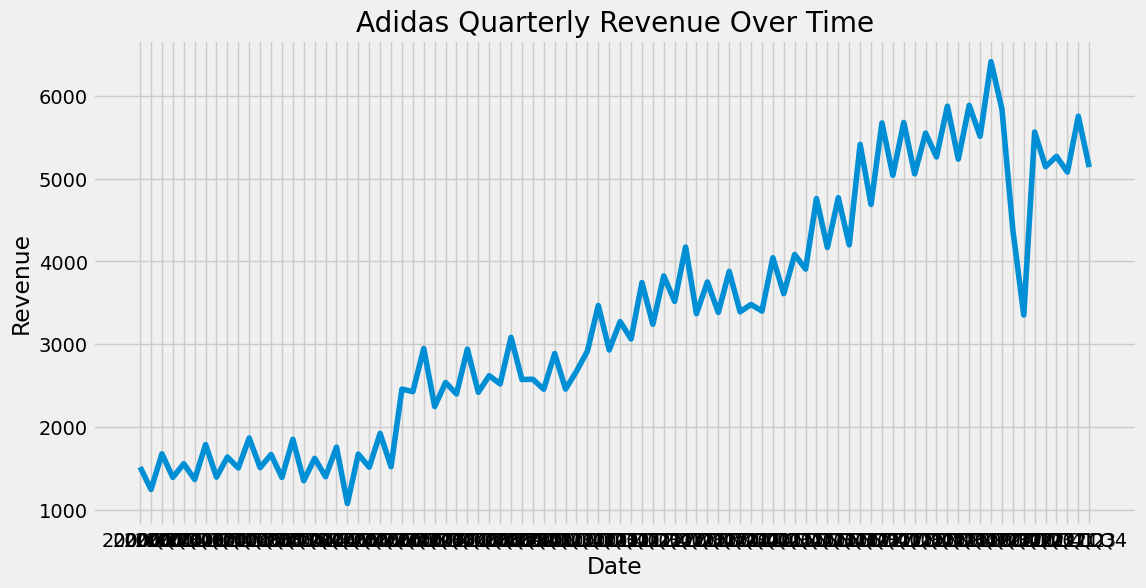

In [88]:
# Time series plot of sales
plt.figure(figsize=(12, 6))
# Access the 'Time Period' from the index using df.index
plt.plot(df.index, df['Revenue'])
plt.title('Adidas Quarterly Revenue Over Time')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()